## Exercise: Final EDA Workflow

You are a data scientist working for a financial services company. The company wants to predict which customers are likely to miss payment within the next 60 days. You receive a dataset containing:
- Customer demographics.
- Accounot balances.
- Historical payment records.
- Transaction activity.
- Credit utilization.
- Customer service interactions.
- Account status.
- Payment delinquency outcomes.

Your task is to design a complete exploratory data analysis and preprocessing workflow.

### Project Requirements

Chapter 5 Capstone Checklist
- Problem definition: Define the target, observation unit, prediction timestamp, and success metrics.
- Dataset inspection: Identify features, data types, identifiers, and structural issues.
- Data quality audit: Check missingness, duplicates, invalid values, and inconsistent categories.
- Univariate EDA: Analyze numerical and categorical distributions.
- Multivariate EDA: Investigate correlations, feature relationships, and interactions.
- Target analysis: Evaluate class imbalance and relationships with candidate predictors.
- Leakage audit: Identify unavailable future information and invalid feature construction.
- Evaluation design: Choose a train-validation-test strategy appropriate for 60-day outcomes.
- Preprocessing pipeline: Implement leakage-safe imputation, encoding, and scaling.
- Baseline modeling: Train a baseline model and evaluate appropriate metrics.
- Documentation: Summarize findings, assumptions, limitations, and recommended next steps.

### Expected Deliverables

A complete submission should include a reproducible Jupyter notebook, a documented preprocessing pipeline, appropriate evaluation results, and a written summary of findings.

A strong submission should explain not only what was done, but why each decision was appropriate for the business problem and data structure.

### Stage 1 — Problem Definition

Define the target, observation unit, prediction timestamp, and success metrics. The example dataset has been loaded below.

**Business objective:** Predict which customers are likely to miss at least one scheduled payment within the next 60 days, enabling the financial services company to prioritize preventive outreach.

**Observation unit:** One customer at a monthly snapshot date.

**Prediction timestamp:** The first day of each month, using only information available at that time.

**Target:** A binary variable indicating whether the customer misses at least one scheduled payment during the subsequent 60 days.

**Evaluation:** Use average precision and ROC-AUC to evaluate ranking, precision and recall at operational thresholds, and potentially precision@K for a capacity-constrained outreach program.

**Validation strategy:** Chronological train-validation-test splitting, with safeguards ensuring labels are fully observable at each historical training cutoff.

### Stage 2 — Building and Inspecting Our Dataset

Identify features, data types, identifiers, and structural issues.

#### 2.1 — Dataset Design
We'll simulate 1,000 customers observed monthly for 24 months, producing 24,000 customer-month records. Each row will represent the information available about a customer at a monthly prediction snapshot. Our target will be whether the customer misses at least one scheduled payment in the following 60 days.

| Feature | Description | Type |
| :--- | :--- | :--- |
| `customer_id` | Unique customer identifier | Identifier |
| `snapshot_date` | Monthly prediction timestamp | Datetime |
| `age` | Customer age | Numerical |
| `annual_income` | Estimated annual income | Numerical |
| `account_balance` | Outstanding account balance | Numerical |
| `credit_utilization` | Proportion of available credit used | Numerical |
| `transactions_30d` | Number of transactions in the preceding 30 days | Numerical, discrete |
| `late_payments_12m` | Number of historical late payments | Numerical, discrete |
| `account_tenure_months` | Months since account opening | Numerical, discrete |
| `employment_status` | Employment category | Categorical |
| `region` | Customer region | Categorical |
| `missed_payment_date` | Future missed-payment outcome | Binary target |

We'll also introduce a small number of deliberate data-quality problems in a later stage so you can practice identifying them rather than being told exactly where they are.

**Important modeling distinction**

This dataset will simulate a coherent 60-day outcome process from underlying monthly payment events. That matters because consecutive monthly snapshots have overlapping prediction horizons. For example, a missed payment in March could legitimately produce a positive label for both a February and March snapshot. We should not independently generate unrelated 60-day labels for every monthly row.

#### 2.2 — Creating the Dataset
The generator creates historical missed-payment events and derives each 60-day target from those events. It also uses a fixed random seed so the dataset is reproducible.

Two limitations to remember: this is synthetic data, and the historical features are simulated summaries rather than features reconstructed from a complete transaction ledger. We'll use it to learn the workflow, not to draw real financial conclusions.

#### 2.3 — Set Up Your Notebook
Place the CSV in the same folder as your notebook and load the data into the notebook.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PATH = './../datasets/financial_customer_months.csv'

def readData(path):    
    dataframe = pd.read_csv(
        path
    )
    return dataframe

df = readData(PATH)

#### 2.4 — Structural Inspection

In Chapter 5.2, we discussed understanding the dataset before making transformations. I want you to write Python code to answer these questions.

**Task A — Basic structure**
1. How many rows and columns are in the dataset?
2. What are the first five observations?
3. What are the data types of each column?
4. How many non-null observations does each column contain?
5. What descriptive statistics can we obtain for numerical and categorical features?

Hints: Think about the Pandas methods shape, head(), dtypes, info(), and describe().

**Task B — Feature classification**

Identify which columns are:
- Numerical continuous.
- Numerical discrete.
- Categorical nominal.
- Identifiers.
- Datetime.
- Target.

A feature being stored as an integer does not necessarily mean it should be treated as a numerical predictor. For example, customer_id is stored numerically, but its magnitude has no meaningful quantitative relationship with payment risk.

**Task C — Understand the observation unit**

Write code to answer:
1. How many unique customers exist?
2. How many unique snapshot dates exist?
3. How many observations exist per customer?
4. What is the earliest snapshot date?
5. What is the latest snapshot date?

Then answer this conceptual question: Why would counting duplicated customer_id values be misleading when determining whether this dataset contains duplicate observations?

**Task D — Identify a potential data type problem**

Inspect the data type of snapshot_date. Pandas often reads dates from CSV files as strings. What would you do to ensure this column is represented as a proper datetime type, and why does that matter for our later temporal splitting?

In [28]:
# Task A - Basic Structure
print('---Basic Structure of the Dataset---')

print('\n---Shape of the dataset:---')
print(df.shape)

print('\n---First 5 rows of data:---')
print(df.head())

print('\n---Datatype of each column:---')
print(df.dtypes)

print('\n---Number of non-null observations in each column:---')
df.info()

print('\n---Descriptive statistics for numerical and categorical features:---')
df.describe(include='all')

---Basic Structure of the Dataset---

---Shape of the dataset:---
(24000, 12)

---First 5 rows of data:---
   customer_id snapshot_date  age  annual_income  account_balance  \
0        10001    2024-01-01   47       42481.25          2231.11   
1        10002    2024-01-01   61       69380.81          5855.66   
2        10003    2024-01-01   34       52645.80          6305.26   
3        10004    2024-01-01   28       44475.26          5096.54   
4        10005    2024-01-01   71       45374.93          2588.58   

   credit_utilization  transactions_30d  late_payments_12m  \
0              0.2342                19                  0   
1              0.4547                14                  0   
2              0.5199                20                  0   
3              0.2667                26                  0   
4              0.2399                19                  0   

   account_tenure_months employment_status     region  missed_payment_60d  
0                     42     

,customer_id,snapshot_date,age,annual_income,account_balance,credit_utilization,transactions_30d,late_payments_12m,account_tenure_months,employment_status,region,missed_payment_60d
count,24000.000000,24000,24000.000000,24000.00000,24000.000000,24000.000000,24000.000000,24000.000000,24000.000000,24000,24000,24000.000000
unique,NaN,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,4,NaN
top,NaN,2024-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Employed,Northeast,NaN
freq,NaN,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16800,6144,NaN
mean,10500.500000,NaN,48.313000,77204.48691,4688.554498,0.397754,18.389042,0.302458,72.598000,NaN,NaN,0.067292
std,288.681005,NaN,16.164341,40283.67506,2421.885488,0.207989,4.842606,0.586934,35.877133,NaN,NaN,0.250532
min,10001.000000,NaN,21.000000,18000.00000,0.000000,0.000000,4.000000,0.000000,1.000000,NaN,NaN,0.000000
25%,10250.750000,NaN,34.000000,48926.50250,2917.317500,0.241400,15.000000,0.000000,42.000000,NaN,NaN,0.000000
50%,10500.500000,NaN,48.500000,68299.47000,4599.345000,0.385600,18.000000,0.000000,73.000000,NaN,NaN,0.000000
75%,10750.250000,NaN,63.000000,95618.50250,6345.735000,0.543100,21.000000,0.000000,103.000000,NaN,NaN,0.000000


The target variable has a mean of approximately:
$$
\bar y = 0.067292
$$
Because `missed_payment_60d` is binary, its mean equals the proportion of positive observations.

Therefore:
$$
P(Y = 1) \approx 6.73\%
$$
This tells us that missed payments are relatively rare in our datset. We'll investigate that more thoroughly during target-distribution analysis.


In [29]:
# Task B - Feature Classification
identifier_cols = ['customer_id']

datetime_cols = ['snapshot_date']

continuous_cols = [
    'annual_income',
    'account_balance',
    'credit_utilization'
]

discrete_cols = [
    'age',
    'transactions_30d',
    'late_payments_12m',
    'account_tenure_months'
]

categorical_cols = [
    'employment_status',
    'region'
]

target_col = 'missed_payment_60d'

In [30]:
# Task C - Understand the Oberservation Unit
print('---Understanding the Observational Unit---')

print('\n---Number of unique customers:---')
print(df['customer_id'].nunique())

print('\n---Number of unique snapshot dates:---')
print(df['snapshot_date'].nunique())

print('\n---Number of observations per customer:---')
print(df['customer_id'].value_counts())

print('---\nEarliest snapshot date:---')
print(df['snapshot_date'].min())

print('---\nLatest snapshot date:---')
print(df['snapshot_date'].max())

---Understanding the Observational Unit---

---Number of unique customers:---
1000

---Number of unique snapshot dates:---
24

---Number of observations per customer:---
customer_id
10001    24
10002    24
10003    24
10004    24
10005    24
         ..
10996    24
10997    24
10998    24
10999    24
11000    24
Name: count, Length: 1000, dtype: int64
---
Earliest snapshot date:---
2024-01-01
---
Latest snapshot date:---
2025-12-01


In [31]:
# Task D - Identify a Potential Data Type Problem
print('---Identifying Potential Data Type Problems---')

print('\n---Inspecting the data type of snapshot_date:---')
df['snapshot_date'] = pd.to_datetime(
    df['snapshot_date']
)

print(df['snapshot_date'].dtype)

print('\n---Inspecting duplicate of customer-month records:---')
duplicate_count = df.duplicated(
    subset=['customer_id', 'snapshot_date']
).sum()

print(duplicate_count)

---Identifying Potential Data Type Problems---

---Inspecting the data type of snapshot_date:---
datetime64[us]

---Inspecting duplicate of customer-month records:---
0


#### Interpretation of the Dataset Structure

1. There's 24,000 observations in the dataset representing the 24 customer-month records for each of the 1000 customers.
2. `customer_id` is not an appropriate numerical predictor because it's an identifier. The feature simply identifies individual customers to determine who the record belongs too. Additionally, `customer_id` numerical magnitude is arbitrary which is why we generally exclude it as a numerical predictor.
3. The combination of `customer_id` and `snapshot_date` is more important for duplicate detection than either column individually because individually those columns will have duplicate values that showup naturally from the dataset description. Multiple observations will have the same `customer_id` because the dataset contains information on that customer in multiple months. Multiple oberservations will have the same `snapshot_date` because the dataset contains information on customers' financials from the same month. The combination of the two columns having duplicate values could pose a problem since we shouldn't expect the same customer to have financial information from the same date.
4. We must convert `snapshot_date` before implementing our chronological validation strategy so that we can perform meaningful time-based operations. Relying on strings is fragile and prevents us from using Pandas' full datetime functionality.

### Stage 3 — Data Quality Audit

Check missingness, duplicates, invalid values, and inconsistent categories.

#### 3.1 — What We'll Investigate

Before we visualize relationships or build predictive models, we need to determine whether the dataset is trustworthy. A model can execute successfully and produce convincing metrics while learning from invalid or inconsistent data. Our objective is to identify these issues before making cleaning decisions

| Dimension | Question |
| :--- | :--- |
| Completeness | Are any values missing? |
| Uniqueness | Are there duplicate customer-month records? |
| Validity | Do values satisfy business rules? |
| Consistency | Are related fields logically consistent? |
| Timeliness | Are snapshot dates valid legitimate or erroneous? |
| Outliers | Are extreme values legitimate or erroneous? |

For this stage we'll divide the work into four tasks. We'll begin with missing data and duplicates.

#### 3.2 — Task A: Missing Data Analysis

From your initial inspection, all 12 columns contain 24,000 non-null observations. That suggests the dataset has no missing values. However, df.info() only provides counts. We want a reusable data-quality report.

**Your assignment**

Write Python code that creates a DataFrame containing the following information for every column:
| Column | Missing count | Missing percentage |
| :--- | :--- | :--- |
| `customer_id` | ? | ? |
| `snapshot_date` | ? | ? |
| `age` | ? | ? |
| ... | ... | ... |

The missing percentage should be:
$$
\text{Missing Percentage}_{j} = \frac{\text{Number of missing values in column } j}{\text{Total number of observations}} \times 100
$$

Hints: Use `isna()`, `sum()`, `len(df)`, and `pd.DataFrame()`.

Additional conceptual question: Suppose 15% of `annual_income` values were missing. Would you immediately replace those values with the mean income? Explain why or why not, referring to the missing-data mechanisms we studied: MCAR, MAR, MNAR.

In [32]:
missing_counts = df.isna().sum()

missing_percentages = (
    missing_counts / len(df)
) * 100

df_missing = pd.DataFrame({
    'missing_count': missing_counts,
    'missing_percentage': missing_percentages
})

display(df_missing)

,missing_count,missing_percentage
customer_id,0,0.0
snapshot_date,0,0.0
age,0,0.0
annual_income,0,0.0
account_balance,0,0.0
credit_utilization,0,0.0
transactions_30d,0,0.0
late_payments_12m,0,0.0
account_tenure_months,0,0.0
employment_status,0,0.0


#### 3.3 — Task B: Duplicate Detection

We established that out observation unit is customer-month. Therefore, duplicate detection must respect that structure.

Write code to calculate:
1. The number of fully duplicated rows.
2. The number of duplicated customer-month keys.
3. The number of customers appearing more than once.
4. Whether every customer has exactly 24 monthly observations.

Hints: You'll need `duplicated()`, `value_counts()`, and possibly `groupby()`.

Conceptual question: Suppose we discover two rows with the same `customer_id` and `snapshot_date`, but different `account_balance` values. Should we automatically delete one of them? Explain what you would investigate before deciding how to resolve the conflict.


In [33]:
# 1. Number of fully duplicated rows
full_duplicates = df.duplicated().sum()

# 2. Number of duplicated customer-month keys
key_duplicates = df.duplicated(
    subset=['customer_id', 'snapshot_date']
).sum()

# 3. Number of customers appearing more than once
customer_counts = df['customer_id'].value_counts()

repeated_customers = (
    customer_counts > 1
).sum()

# 4. Does every customer have exactly 24 observations?
all_have_24 = (
    customer_counts == 24
).all()

#### 3.4 — Task C: Numerical Range Validation, Categorical Validation, and Target Validation
**Numerical Range Validation**

Write code that counts the number of observations violating each numerical rule. For example, to identify invalid ages:
``
invalid_age = (
    (df["age"] < 18) |
    (df["age"] > 100)
)

print("Invalid ages:", invalid_age.sum())
``

Here, `|` represents elementwise logical OR. You can also use & for logical AND. Your assignment: Implement similar checks for annual income, account balance, credit utilization, transactions, late payments, and account tenure. Don't remove or modify invalid observations yet.

**Categorical Validation**

First, investigate the categories that actually exist.
``
print(df["employment_status"].unique())
print(df["region"].unique())
``

Then define the expected categories based on our dataset's documentation. For example:
``
valid_employment = {
    "Employed",
    "Self-employed",
    "Unemployed",
    "Retired"
}
``

You can use `.isin()` to determine whether each observation belongs to the accepted set. Your assignment: Count invalid employment statuses and invalid regions.

**Target Validation**
Our target should be binary:
$$
Y \in \{0, 1\}
$$

Write code that verifies whether every value in missed_payment_60d belongs to that set. Think about using .isin() together with one of the Boolean aggregation methods we just practiced.

In [34]:
# Numerical Range Validation
invalid_income = (
    df["annual_income"] < 0
)

invalid_balance = (
    df["account_balance"] < 0
)

invalid_credit = (
    (df["credit_utilization"] > 1.0) |
    (df["credit_utilization"] < 0.0)
)

invalid_age = (
    (df["age"] < 18) |
    (df["age"] > 100)
)

invalid_transactions = (
    df["transactions_30d"] < 0
)

invalid_payments = (
    df["late_payments_12m"] < 0
)

invalid_tenure = (
    df["account_tenure_months"] <= 0
)

numerical_validation = pd.DataFrame({
    "feature": [
        "annual_income",
        "account_balance",
        "credit_utilization",
        "age",
        "transactions_30d",
        "late_payments_12m",
        "account_tenure_months"
    ],
    "invalid_count": [
        invalid_income.sum(),
        invalid_balance.sum(),
        invalid_credit.sum(),
        invalid_age.sum(),
        invalid_transactions.sum(),
        invalid_payments.sum(),
        invalid_tenure.sum()
    ]
})

display(numerical_validation)

,feature,invalid_count
0,annual_income,0
1,account_balance,0
2,credit_utilization,0
3,age,0
4,transactions_30d,0
5,late_payments_12m,0
6,account_tenure_months,0


In [35]:
# Categorical Validation
print(df["employment_status"].unique())
print(df["region"].unique())

valid_employment = {
    "Employed",
    "Retired",
    "Self-employed",
    "Unemployed"
}

df["employment_status"].isin(valid_employment)

invalid_employment = (
    ~df["employment_status"].isin(valid_employment)
)

valid_region = {
    "South",
    "Northeast",
    "West",
    "Midwest"
}

df["region"].isin(valid_region)

invalid_region = (
    ~df["region"].isin(valid_region)
)

categorical_validation = pd.DataFrame({
    "feature": [
        "employment_stats",
        "region"
    ],
    "invalid_count": [
        invalid_employment.sum(),
        invalid_region.sum()
    ]
})

display(categorical_validation)

<ArrowStringArray>
['Employed', 'Retired', 'Self-employed', 'Unemployed']
Length: 4, dtype: str
<ArrowStringArray>
['South', 'Northeast', 'West', 'Midwest']
Length: 4, dtype: str


,feature,invalid_count
0,employment_stats,0
1,region,0


In [36]:
# Target Validation
valid_target = (
    df["missed_payment_60d"].isin([1, 0]).all()
)

print("All target values valid:", valid_target)

invalid_target_count = (
    ~df["missed_payment_60d"].isin([0, 1])
).sum()

All target values valid: True


#### 3.5 — Cross Feature Consistency

Individual columns can satisfy their ranges while still being inconsistent with one another. For example, suppose we have a 21-year-old customer with an account tenure of 240 months (20 years). Both values might pass their individual checks, but the customer would have opened the account at age 1. That warrants investigation. A useful derived quantity is:
$$
\text{Age at account opening} = \text{Current age} - \frac{\text{Account tenure months}}{12}
$$

For this exercise, assume customers must have been at least 18 when they opened their accounts.

Task: Write code to calculate how many observations imply an account-opening age below 18. Keep in mind that age is rounded to whole years, so the resulting age is only approximate. A real validation system would ideally use dates of birth and account-opening dates.

In [37]:
# Cross-Feature Consistency
age_at_opening = (
    df["age"] - 
    df["account_tenure_months"] / 12
)

invalid_opening_age = (
    age_at_opening < 18
)

# Count the observations violating the rule
invalid_opening_count = invalid_opening_age.sum()

print("Invalid account-opening ages:", invalid_opening_count)

# Display the relevant records for investigation
flagged_openings = df.loc[
    invalid_opening_age,
    ["customer_id", "snapshot_date", "age", "account_tenure_months"]
].copy()

flagged_openings["estimated_opening_age"] = age_at_opening.loc[
    invalid_opening_age
]

display(flagged_openings.head(10))


Invalid account-opening ages: 1645


,customer_id,snapshot_date,age,account_tenure_months,estimated_opening_age
7,10008,2024-01-01,23,77,16.583333
16,10017,2024-01-01,23,67,17.416667
25,10026,2024-01-01,23,118,13.166667
69,10070,2024-01-01,22,50,17.833333
97,10098,2024-01-01,26,113,16.583333
98,10099,2024-01-01,21,94,13.166667
102,10103,2024-01-01,21,70,15.166667
110,10111,2024-01-01,22,74,15.833333
117,10118,2024-01-01,26,111,16.750000
123,10124,2024-01-01,27,110,17.833333


### 3.6 — Outlier Detection and Investigation

We can now move into the next stage of the project. In the previous stage we asked: *Does each observation satisfy the rules of the dataset?* Now were asking: **Which observations are statistically unusual, and are those unusual observations meaningful or problematic?** A customer with an annual income of $300,000 may be statistically unusual but completely legitimate. A customer with credit utilization of 1.8 would violate our defined range and represent a different type of problem.

**Task A: IQR-Based Outlier Detection**

The interquartile range is:
$$

$$

Using the conventional Tukey fences, observations are flagged when:
$$
IQR = Q_3 - Q_1
$$
x < Q_1 - 1.5(IQR)
or
$$
x > Q_3 + 1.5(IQR)
$$

These are statistical screening rules, not proof that an observation is erroneous.

**Your assignment**

For each of the following features:
- annual_income
- account_balance
- credit_utilization
- transactions_30d

Calculate the first quartile, third quartile, IQR, lower fence, upper fence, number of outliers, and percentage of observations flagged. Your final output should be a DataFrame with the following structure:
| feature | Q1 | Q3 | IQR | lower_bound | upper_bound | outlier_count | outlier_pct |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| annual_income | ... | ... | ... | ... | ... | ... | ... |
| account_balance | ... | ... | ... | ... | ... | ... | ... |

Hint: Use the following Pandas methods:
``
df[column].quantile(0.25)
df[column].quantile(0.75)
``

Create a Boolean mask to identify values outside the fences, then use .sum() to count them. You can use a for loop and append dictionaries to a list before constructing your summary DataFrame.

**Task B: Z-Score Outlier Detection**
The Z-score measures how many standard deviations an observation lies from the mean:
$$
z_i = \frac{x_i - \mu}{\sigma}
$$

For this exercise, classify observations as potential outliers when:
$$
|z_i| > 3
$$
Apply this method to `annual_income` and `account_balance`.

Calculate the number of observations flagged for each feature and compare the results with the IQR method. Think about: Why might the IQR and Z-score methods flag different numbers of observations, especially when income distributions are right-skewed?

**Task C: Interpretation**
Answer these questions after completing the calculations.
1. Suppose IQR flags 8% of annual incomes as outliers, but the Z-score method flags only 2%. Does that mean one method is incorrect? Explain.
2. Why might deleting high-income customers introduce bias into a model predicting missed payments?
3. If an observation has unusually high credit utilization but still falls within the valid range of 0 to 1, should it automatically be removed?

In [38]:
# IQR-Based Outlier Detection
features = [
    "annual_income",
    "account_balance",
    "credit_utilization",
    "transactions_30d"
]

results = []

for feature in features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    )

    results.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outliers.sum(),
        "outlier_pct": outliers.mean() * 100
    })

iqr_outlier_detection = pd.DataFrame(results)

display(iqr_outlier_detection)

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
0,annual_income,48926.5025,95618.5025,46692.0000,-21111.49750,165656.50250,936,3.900000
1,account_balance,2917.3175,6345.7350,3428.4175,-2225.30875,11488.36125,52,0.216667
2,credit_utilization,0.2414,0.5431,0.3017,-0.21115,0.99565,29,0.120833
3,transactions_30d,15.0000,21.0000,6.0000,6.00000,30.00000,285,1.187500


In [40]:
# Z-Score Outlier Detection
features = ["annual_income", "account_balance"]

results = []

for feature in features:
    z_scores = (
        (df[feature] - df[feature].mean()) / 
        df[feature].std()
    )

    flagged = z_scores.abs() > 3

    results.append({
        "feature": feature,
        "flagged_observations": flagged.sum(),
        "flagged_pct": flagged.mean() * 100
    })

    z_score_outlier_detection = pd.DataFrame(results)

display(z_score_outlier_detection)

,feature,flagged_observations,flagged_pct
0,annual_income,408,1.700000
1,account_balance,26,0.108333


1. No it doesn't mean that either one is incorrect. The distinction is that IQR uses quartiles, while Z-scores use the mean and standard deviation. For a right-skewed income distribution, extreme high incomes can increase both the mean and standard deviation, making the Z-score threshold less sensitive to some high-income observations. IQR uses the middle 50% of the data and is less affected by extreme values.
2. Deleting legitimate high-income customers would change the population represented by the training dataset introducing selection bias. It could also eliminate relationships between income and missed-payment behavior that the model should learn.
3. An unusual observation is not necessarily erroneous. In fact, high credit utilization could be particularly informative for predicting missed payments. Automatically deleting those observations could eliminate valuable predictive information.

### 3.7 — Investigating Outlier Concentration

**Task D:** Investigating Outlier Concentration

I want you to write the next piece of code yourself. Using your annual-income IQR boundary, calculate:
1. The number of unique customers represented among the 936 flagged observations.
2. The number of flagged observations per customer.
3. The five customers with the most flagged observations.
4. The percentage of all 1,000 customers who have at least one flagged income observation.

Hint: First, recreate the Boolean mask using the upper and lower bounds already stored in `iqr_outlier_detection`.

You can access the income row using:

``
income_row = iqr_outlier_detection.loc[
    iqr_outlier_detection["feature"] == "annual_income"
].iloc[0]
``

Then retrieve its boundaries:

``
lower = income_row["lower_bound"]
upper = income_row["upper_bound"]
``

Create a Boolean mask identifying the outliers. You already know how to do this.

Next, consider these Pandas methods:
| Method | Purpose |
| :--- | :--- |
| `.loc[]` | Filter the dataset using a Boolean mask |
| `.nunique()` | Count distinct customers |
| `.value_counts()` | Count flagged observations per customer |
| `.head(5)` | Show the five highest counts |

Try to calculate the customer percentage without my giving you the formula in code.


In [56]:
# Investigating Outlier Concentration
income_row = iqr_outlier_detection.loc[
    iqr_outlier_detection["feature"] == "annual_income"
].iloc[0]

lower = income_row["lower_bound"]
upper = income_row["upper_bound"]

# Identify outlier observations
income_outliers = (
    (df["annual_income"] < lower) |
    (df["annual_income"] > upper)
)

# Number of unique customers flagged
unique_flagged_customers = df.loc[
    income_outliers, "customer_id"
].nunique()

# Number of flagged observations per customer
flagged_counts = df.loc[
    income_outliers, "customer_id"
].value_counts()

# Top five most frequently flagged customers
top_five = flagged_counts.head(5)

# Percentage of unique customers flagged
percentage_customers_flagged = (
    unique_flagged_customers / df["customer_id"].nunique()
) * 100

print("Total flagged observations:", income_outliers.sum())
print("Unique flagged customers:", unique_flagged_customers)
print("Percentage of customers flagged:", percentage_customers_flagged)

display(top_five)

Total flagged observations: 936
Unique flagged customers: 39
Percentage of customers flagged: 3.9


customer_id
10007    24
10009    24
10040    24
10068    24
10070    24
Name: count, dtype: int64

In [58]:
high_income = df["annual_income"] > upper
low_income = df["annual_income"] < lower

print("High-income outlier customers:",
      df.loc[high_income, "customer_id"].nunique())

print("Low-income outlier customers:",
      df.loc[low_income, "customer_id"].nunique())

High-income outlier customers: 39
Low-income outlier customers: 0


## Stage 4 — Univariate Exploratory Data Analysis

We've completed Stage 3, where we evaluated the quality and reliability of our dataset. Now we'll move into Stage 4: Univariate Exploratory Data Analysis (EDA).

The distinction is important:
- Stage 3: Can we trust the data?
- Stage 4: What can we learn about each individual variable?
- Stage 5: How do variables relate to one another and to our target?

Throughout this stage, you'll continue writing the Python code yourself. I'll explain the theory, establish the tasks, provide hints where appropriate, and review your implementation and interpretations.

### 4.1 — Objectives and Scope

By the end of Stage 4, you should be able to:
1. Characterize numerical distributions using descriptive statistics and visualizations.
2. Identify skewness, symmetry, heavy tails, and potential multimodality.
3. Understand how mean, median, variance, standard deviation, and quantiles describe different properties of a distribution.
4. Analyze categorical variables using frequency distributions.
5. Investigate the target variable's class balance.
6. Recognize distributional properties that may influence feature preprocessing and modeling.

We will not examine feature–target relationships or correlations yet. Those belong in Stage 5.

### 4.2 — Dataset Overview

We'll continue working with the same customer financial dataset.
| Observations | Customers | Monthly snapshots|
| :-: | :-: | :-: |
| **24,000** | **1,000** | **24** |

Target: `missed_payment_60` - binary classification 

We'll analyze the following feature groups:
| Type | Features |
| :- | :- |
| Continuous numerical | `annual_income`, `account_balance`, `credit_utilization` |
| Discrete numerical | `age`, `transactions_30d`, `late_payments_12`, `account_tenure_months` |
| Categorical | `employment_status`, `region` |
| Binary target | `missed_payment_60d` |

We'll retain `customer_id` and `snapshot_date` for identifying records and understanding temporal structure, but not treat them as ordinary numerical predictors.

### 4.3 — Numerical Distribution Analysis

#### 4.3.1 — Measures of Central Tendency

The first step is understanding where values are concentrated. Three common measures are:

**Mean**
$$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$$
The arithmetic average of all observations.

**Median**

The middle value after sorting the observations. The median corrsponds to the 50th percentile.

**Mode**
The most frequently occurring value. These statistics describe different aspects of a distribution. For example, consider annual incomes:
$$X = [40{,}000,\ 45{,}000,\ 50{,}000,\ 55{,}000,\ 300{,}000]$$
The mean is:
$$\bar{x} = 98{,}000$$
The median is:
$$\tilde{x} = 50{,}000$$
Notice that the mean is substantially larger because of the $300,000 observation. This illustrates why the median is often more representative of a typical observation in a strongly right-skewed distribution.

#### 4.3.2 — Measures of Dispersion

Central tendency alone does not describe how widely values are spread.

**Sample variance**
$$s^2 = \frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})^2$$
**Sample standard deviation**
$$s = \sqrt{\frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})^2}$$
**Interquartile range**
$$IQR = Q_3 - Q_1$$
Variance and standard deviation are sensitive to extreme values because they involve squared deviations from the mean. The IQR measures the spread of the middle 50% of observations and is generally more robust to extreme values.

#### 4.3.3 — Skewness
Skewness describes asymmetry in a distribution. A commonly used moment-based sample skewness statistic is based on:
$$
g_1 = \frac{\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^3}{\left(\frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^2\right)^{3/2}}
$$
Pandas' `.skew()` uses a bias-adjusted version of sample skewness.

![](../images/4.3.3-skewness.png)

We already observed that annual income is strongly right-skewed. Now we'll quantify that observation.

### 4.4 — Task A: Descriptive Statistics

**Your assignment**

Create a summary DataFrame for the seven numerical features. Your summary should contain:
| Statistic | Description |
| :- | :- |
| `mean` | Average value |
| `median` | 50th percentile |
| `std` | Sample standard deviation |
| `min` | Minimum |
| `Q1` | 25th percentile |
| `Q3` | 75th percentile |
| `max` | Maximum |
| `IQR` | Interquartile range |
| `skewness` | Distribution asymmetry |

The final DataFrame should have one row per numerical feature and one column per statistic. You may use:
```
df[numerical_cols].mean()
df[numerical_cols].median()
df[numerical_cols].std()
df[numerical_cols].quantile(0.25)
df[numerical_cols].quantile(0.75)
df[numerical_cols].skew()
```
Try constructing the DataFrame yourself rather than copying a complete solution.

**Interpretation questions**
1. Which feature has the greatest positive skewness?
2. For annual income, how does the mean compare with the median? Does that agree with the histogram?
3. Which numerical features have substantial dispersion relative to their typical values?
4. Why should we avoid comparing raw standard deviations across variables measured in very different units?

In [73]:
# Descriptive Statistics
numerical_features = [
    "annual_income",
    "account_balance",
    "credit_utilization",
    "age",
    "transactions_30d",
    "late_payments_12m",
    "account_tenure_months"
]

results = []

for feature in numerical_features:
    results.append({
        "feature": feature,
        "mean": df[feature].mean(),
        "median": df[feature].median(),
        "std": df[feature].std(),
        "min": df[feature].min(),
        "Q1": df[feature].quantile(0.25),
        "Q3": df[feature].quantile(0.75),
        "max": df[feature].max(),
        "IQR": (
            df[feature].quantile(0.75)
            - df[feature].quantile(0.25)
        ),
        "skewness": df[feature].skew()
    })

summary = pd.DataFrame(results).set_index("feature")

display(summary)

,mean,median,std,min,Q1,Q3,max,IQR,skewness
feature,,,,,,,,,
annual_income,77204.486910,68299.4700,40283.675060,18000.0,48926.5025,95618.5025,300000.00,46692.0000,1.536076
account_balance,4688.554498,4599.3450,2421.885488,0.0,2917.3175,6345.7350,13368.18,3428.4175,0.233684
credit_utilization,0.397754,0.3856,0.207989,0.0,0.2414,0.5431,1.00,0.3017,0.253378
age,48.313000,48.5000,16.164341,21.0,34.0000,63.0000,75.00,29.0000,-0.025969
transactions_30d,18.389042,18.0000,4.842606,4.0,15.0000,21.0000,44.00,6.0000,0.321910
late_payments_12m,0.302458,0.0000,0.586934,0.0,0.0000,0.0000,5.00,0.0000,2.162645
account_tenure_months,72.598000,73.0000,35.877133,1.0,42.0000,103.0000,143.00,61.0000,-0.015412


1. late payments has the largest positive skew.
2. The mean for annual income is larger than the median which lines up with the histogram.
3. annual income and account balance have the largest statistical dispersion from their respective means. Their relative variability is actually quite similar, despite the large difference in raw standard deviations. This measure is useful for positive, ratio-scale variables with meaningful nonzero means. It is less informative when the mean is near zero.
4. These features are not standardized so comparing their raw standard deviations could lead to incorrect interpretations about the distributions of the respective features.

### 4.5 — Task B: Distribution Visualization
You've already successfully generated a 2×2 grid of histograms for:
- `annual_income`
- `account_balance`
- `credit_utilization`
- `transactions_30d`

We won't repeat that work. Instead, extend the visualization to include the remaining numerical features:
- `age`
- `late_payments_12m`
- `account_tenure_months`

For this task, choose an appropriate visualization for each feature. Consider whether a histogram or discrete count plot is more informative. Pay particular attention to late_payments_12m, where many observations may have a value of zero.

**Interpretation questions**
1. Is the distribution of late_payments_12m symmetric, skewed, or concentrated at particular values?
2. Does the distribution of age look approximately uniform, bell-shaped, or something else?
3. What does the distribution of account_tenure_months tell us about the composition of the customer population?

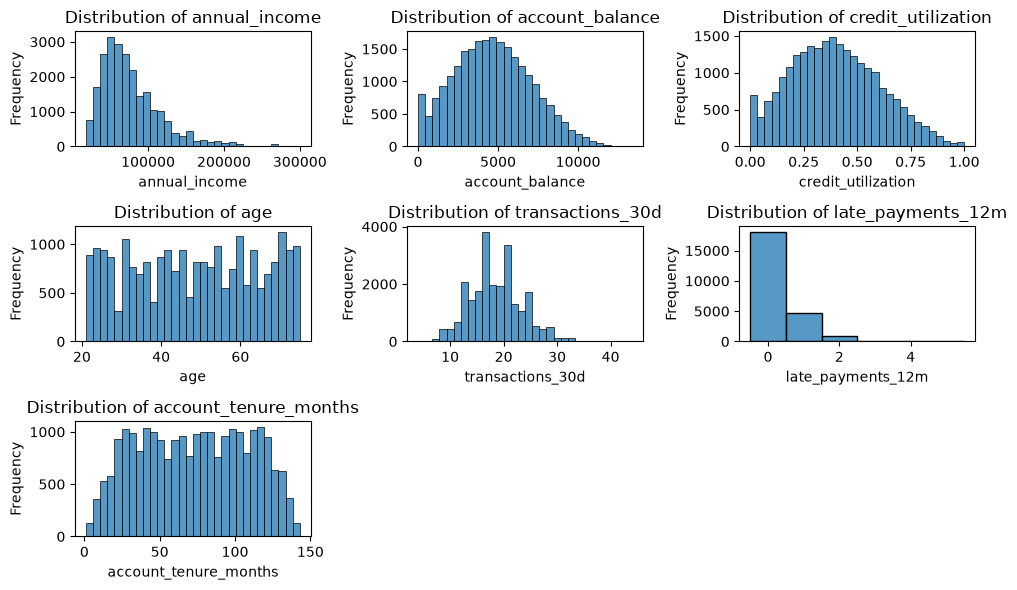

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution Visualization
# Create the figure once
fig, axes = plt.subplots(
    nrows=3, 
    ncols=3, 
    figsize=(10, 6)
)

# Pair each feature with one subplot
for feature, ax in zip(numerical_features, axes.flat):
    if feature == "late_payments_12m":
        sns.histplot(
            data=df,
            x=feature,
            discrete=True,
            ax=ax
        )
    else:
        sns.histplot(
            data=df,
            x=feature,
            bins=30,
            ax=ax
        )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

# Remove unused axes
for ax in axes.flat[len(numerical_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

1. Not sure because I dont see anything in that particular histogram
2. The distribution of late payments looks approximately right skewed. Late payments are concentrated at zero, with a smaller number of customers having multiple late payments.
3. Most of the customers have an account tenure between around 25 to 125 months. The distribution between those values is approximately uniform.

### 3.8 — Distribution Analysis and Visualization

We've completed the numerical investigation of outliers. Now we're going to examine the underlying distributions visually. The objective is to understand what our features look like, how they differ across customers, and whether their distributions suggest transformations or further investigation before modeling.

**Task A: Histograms and Distribution Shape**

For each of the following numerical features:
- annual_income
- account_balance
- credit_utilization
- transactions_30d

Create a histogram using Matplotlib or Seaborn. Your code should generate a 2×2 grid of histograms, with an appropriate title and axis labels for each feature. You can use:
```
import matplotlib.pyplot as plt
import seaborn as sns

```
Hints: `plt.subplots()`, `sns.histplot()`, `plt.tight_layout`

Questions to answer:
1. Which features appear approximately symmetric, right-skewed, or left-skewed?
2. Does the annual income distribution visually support the outliers we identified using the IQR method?
3. Why might the shape of a feature's distribution matter when choosing between linear models, distance-based models, and tree-based models?

**Task B: Compare the Observation-Level and Customer-Level Distributions**

This is especially important because our dataset contains repeated observations.

Create two histograms of annual_income:
- One using all 24,000 customer-month observations.
- One using only one observation per customer, giving us 1,000 customer observations.

For the second histogram, you can begin with:
```
customer_level = df.drop_duplicates(subset="customer_id")
```

This is appropriate for the comparison exercise, although in a real longitudinal analysis we'd explicitly choose a reference date or aggregation method.

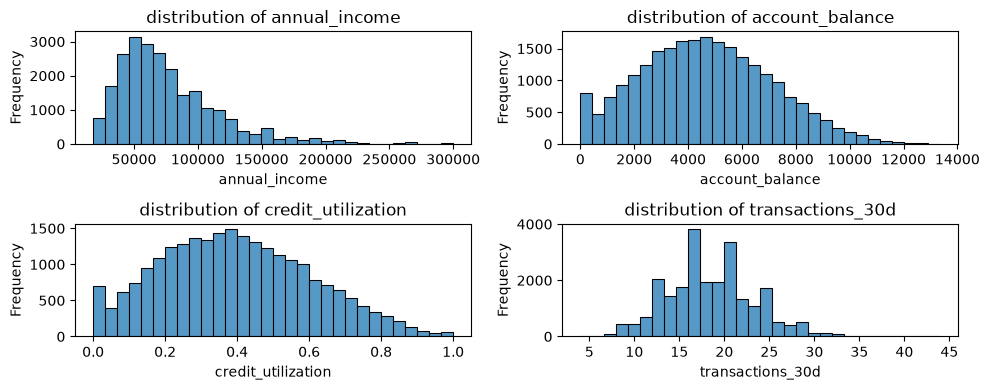

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograms and Distribution Shape
features = [
    "annual_income",
    "account_balance",
    "credit_utilization",
    "transactions_30d"
]

# Create the figure once
fig, axes = plt.subplots(
    nrows=2, 
    ncols=2, 
    figsize=(10,4)
)

# Pair each feature with one subplot
for feature, ax in zip(features, axes.flat):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        ax=ax
    )

    ax.set_title(f"distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

1. 
    - **Annual Income:** Most customers earn approximately $30,000–$100,000, while a smaller number earn substantially more. This produces a long right tail. 
    - **Account balance:** The distribution is roughly bell-shaped, centered around $4,500–$5,000, with a slight right tail.
    - **Credit utilization:** The distribution is unimodal, centered around 0.4, and bounded between 0 and 1. It is not normally distributed, even though it looks approximately symmetric around its peak.
    - **Transactions:** The distribution is approximately symmetric and discrete, with a concentration around 18–20 transactions per month.

    An important distinction is that symmetric does not necessarily mean normally distributed.
2. Yes. The histogram shows a long right tail containing relatively few observations. We previously identified:
    - 936 outlier observations (3.9%).
    - 39 unique customers.
    - All 39 customers were high-income outliers.
    - Each of those customers was flagged in all 24 months.

    The histogram is consistent with those findings. However, there's a subtle distinction worth understanding. Right-skewness does not automatically imply erroneous outliers. Income distributions are frequently right-skewed because earnings are bounded below but can extend to very high values.
    
    In this case, the IQR method identifies unusually high values relative to the rest of the sample. It does not establish that those values are incorrect.
3. Feature distributions inform preprocessing and potential model behavior, but they do not independently determine which model will predict the target best.

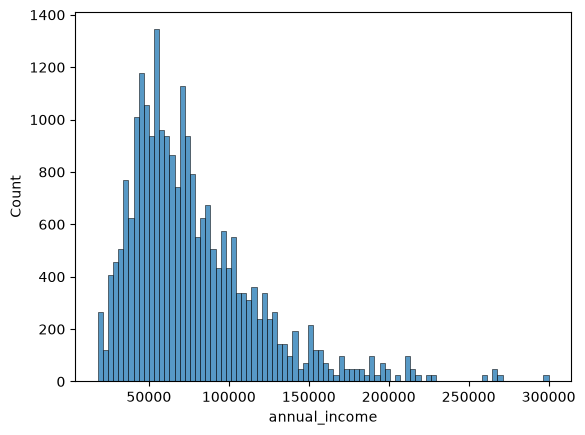

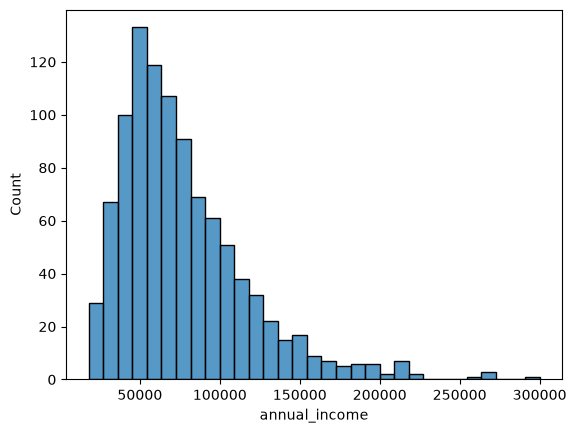

In [ ]:
# Compare the Observation-Level and Customer-Level Distributions
# Observation-Level Distribution
sns.histplot(df["annual_income"])
plt.show()

# Customer-Level Distribution
customer_level = df.drop_duplicates(subset="customer_id")

sns.histplot(customer_level["annual_income"])
plt.show()

### 3.9 — Feature–Target Relationship Analysis
Now that we've studied individual feature distributions, we can investigate how those features relate to our target variable:
```
missed_payment_60d
```

Recall that this is a binary classification problem:
$$
Y = \begin{cases} 
1 & \text{Customer misses a payment within 60 days} \\ 
0 & \text{Customer does not miss a payment} 
\end{cases}
$$

### Stage 4 — Univariate EDA 

Analyze numerical and categorical distributions.

### Stage 5 — Multivariate EDA 

Investigate correlations, feature relationships, and interactions.

### Stage 6 — Target analysis 

Evaluate class imbalance and relationships with candidate predictors.

### Stage 7 — Leakage Audit

Identify unavailable future information and invalid feature construction. 

### Stage 8 — Evaluation Design

Choose a train-validation-test strategy appropriate for 60-day outcomes.